In [2]:
import numpy as np
import matplotlib.pyplot as plt

import pywt

# Add files up one level to the path
import sys
sys.path.append("../..")

import scipy.sparse as sps
from scipy.fft import dct, idct
import jlinops

import sys
import os

from wavelets import WaveletTransformOperator2D

import jlinops




from mpl_toolkits.axes_grid1 import make_axes_locatable
from matplotlib.ticker import FormatStrFormatter

import matplotlib as mpl
from mpl_toolkits.axes_grid1 import make_axes_locatable
import matplotlib.gridspec as gridspec
# mpl.rcParams['text.usetex'] = True
# mpl.rc('text.latex', preamble=r'\usepackage{amsmath}')

# Define the custom style with RGB color values
custom_style = {
    "axes.prop_cycle": plt.cycler(color=[(106/255, 192/255, 205/255),  # blue - C0
                                         (235/255, 186/255, 63/255),  # gold - C1
                                         (172/255, 46/255, 55/255),  # red - C2
                                         (32/255, 82/255, 145/255),  # dark blue - C3
                                         (83/255, 165/255, 106/255),  # green - C4
                                         (239/255, 145/255, 75/255),  # orange - C5
                                         (208/255, 92/255, 89/255),  # pink - C6
                                         (80/255, 67/255, 157/255),  # purple - C7
                                         (82/255, 82/255, 82/255),  # gray - C8
                                         (53/255, 53/255, 53/255),  # charcoal - C9
                                         (30/255, 27/255, 28/255), # black - C10  
                                         ]) 
}
plt.rc('axes', prop_cycle=custom_style['axes.prop_cycle'])


from trips.utilities.operators import create_framelet_operator


from msolver import IASGKS, MMGKS, VanillaGKS
from fsolver import MMFGK
from pgkbsolver import MMGKB

# Setup toy problem

In [7]:
image = jlinops.cameraman()
img_shape = image.shape
ground_truth = image.flatten()

A = jlinops.Gaussian2DBlurOperator(img_shape, blur_sigma=2.0, mode="reflect")
#A = WaveletTransformOperator2D(img_shape, wavelet="haar", level=3)
b_true = A @ ground_truth
noise_level_sigma = 0.03
noise_vec = np.random.normal(size=A.shape[0])
noise_vec /= np.linalg.norm(noise_vec)
noise_vec *= noise_level_sigma*np.linalg.norm(b_true)
noise_var = ( (noise_level_sigma*np.linalg.norm(b_true) )**2 ) / A.shape[0]
noise_sigma = np.sqrt(noise_var)
b = b_true + noise_vec
naive_recon = A.T @ b

In [15]:
C = create_framelet_operator(3,3,1)

/Users/jonathanlindbloom/miniforge3/envs/jlinops/lib/python3.11/site-packages/scipy/sparse/_index.py:100: SparseEfficiencyWarning: Changing the sparsity structure of a csr_matrix is expensive. lil_matrix is more efficient.
  self._set_intXint(row, col, x.flat[0])


In [16]:
Cmat = jlinops.black_box_to_dense(C)

In [17]:
Cmat

array([[ 0.5625    ,  0.1875    ,  0.        ,  0.1875    ,  0.0625    ,
         0.        ,  0.        ,  0.        ,  0.        ],
       [ 0.1875    ,  0.375     ,  0.1875    ,  0.0625    ,  0.125     ,
         0.0625    ,  0.        ,  0.        ,  0.        ],
       [ 0.        ,  0.1875    ,  0.5625    ,  0.        ,  0.0625    ,
         0.1875    ,  0.        ,  0.        ,  0.        ],
       [-0.26516504,  0.26516504,  0.        , -0.08838835,  0.08838835,
         0.        ,  0.        ,  0.        ,  0.        ],
       [-0.26516504,  0.        ,  0.26516504, -0.08838835,  0.        ,
         0.08838835,  0.        ,  0.        ,  0.        ],
       [ 0.        , -0.26516504,  0.26516504,  0.        , -0.08838835,
         0.08838835,  0.        ,  0.        ,  0.        ],
       [ 0.1875    , -0.1875    ,  0.        ,  0.0625    , -0.0625    ,
         0.        ,  0.        ,  0.        ,  0.        ],
       [-0.1875    ,  0.375     , -0.1875    , -0.0625    ,  0

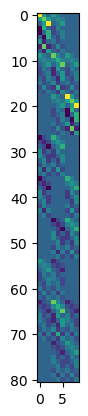

In [18]:
plt.imshow(Cmat)
plt.show()

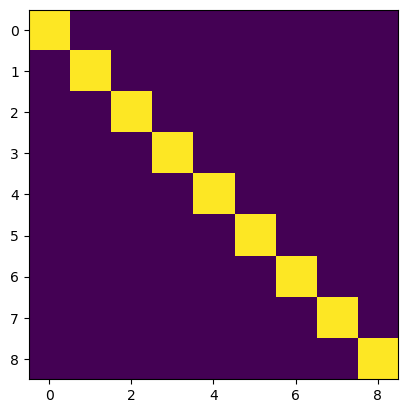

In [22]:
plt.imshow(Cmat.T @ Cmat)
plt.show()

In [24]:
np.linalg.matrix_rank(Cmat)

9

In [25]:
Cmat.shape

(81, 9)

(81, 9)

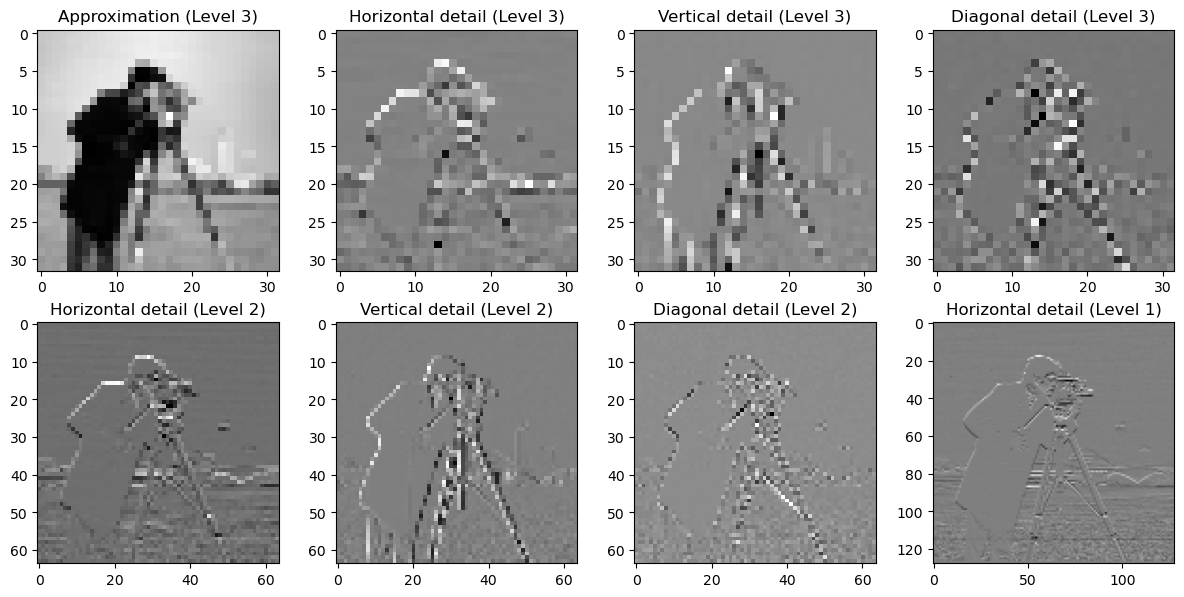

In [4]:
# Create a sample 2D image (e.g., 256x256 random matrix)

# Perform 2D wavelet decomposition using Haar wavelet, with 3 levels
coeffs = pywt.wavedec2(image, 'haar', level=3)

# coeffs is a list containing the approximation coefficients and detail coefficients
# The first element of coeffs is the approximation coefficient at level 3
# The subsequent elements are tuples of detail coefficients (horizontal, vertical, diagonal) for each level

# Extract the approximation coefficients at the final level (level 3)
cA3 = coeffs[0]

# Extract the detail coefficients (cH, cV, cD) for each level
(cH3, cV3, cD3), (cH2, cV2, cD2), (cH1, cV1, cD1) = coeffs[1:]

# Plotting the approximation and detail coefficients for visualization
fig, ax = plt.subplots(2, 4, figsize=(12, 6))

# Level 3 coefficients
ax[0, 0].imshow(cA3, cmap='gray')
ax[0, 0].set_title('Approximation (Level 3)')

ax[0, 1].imshow(cH3, cmap='gray')
ax[0, 1].set_title('Horizontal detail (Level 3)')

ax[0, 2].imshow(cV3, cmap='gray')
ax[0, 2].set_title('Vertical detail (Level 3)')

ax[0, 3].imshow(cD3, cmap='gray')
ax[0, 3].set_title('Diagonal detail (Level 3)')

# Level 2 coefficients
ax[1, 0].imshow(cH2, cmap='gray')
ax[1, 0].set_title('Horizontal detail (Level 2)')

ax[1, 1].imshow(cV2, cmap='gray')
ax[1, 1].set_title('Vertical detail (Level 2)')

ax[1, 2].imshow(cD2, cmap='gray')
ax[1, 2].set_title('Diagonal detail (Level 2)')

# Level 1 coefficients
ax[1, 3].imshow(cH1, cmap='gray')
ax[1, 3].set_title('Horizontal detail (Level 1)')

# Adjust layout and show the plot
plt.tight_layout()
plt.show()


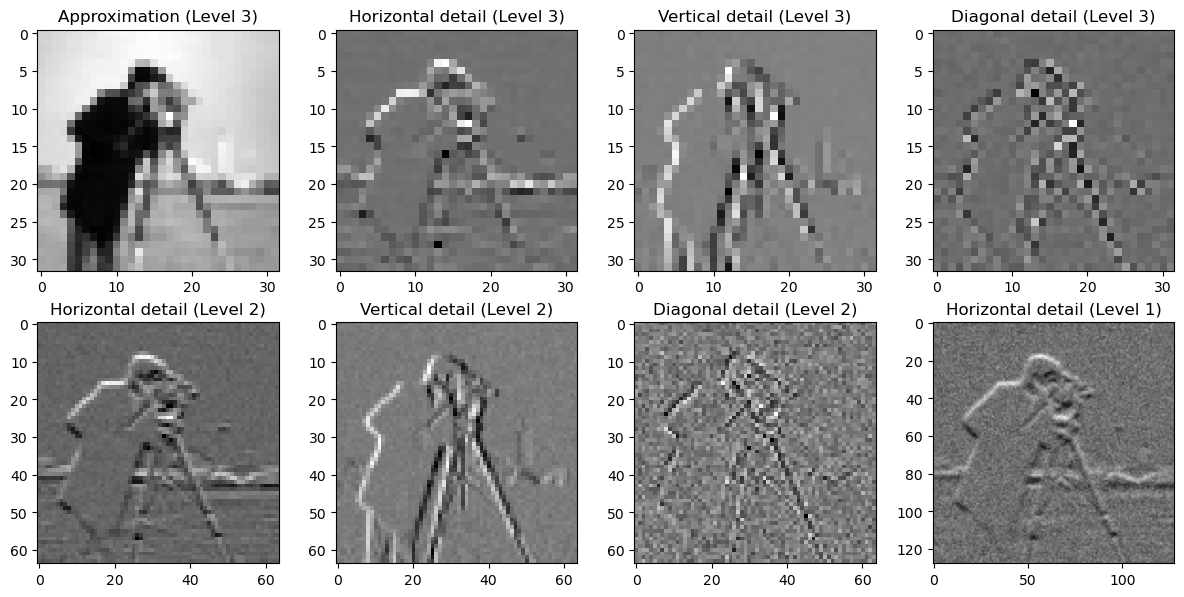

In [5]:
# Create a sample 2D image (e.g., 256x256 random matrix)

# Perform 2D wavelet decomposition using Haar wavelet, with 3 levels
coeffs = pywt.wavedec2(b.reshape(img_shape), 'haar', level=3)

# coeffs is a list containing the approximation coefficients and detail coefficients
# The first element of coeffs is the approximation coefficient at level 3
# The subsequent elements are tuples of detail coefficients (horizontal, vertical, diagonal) for each level

# Extract the approximation coefficients at the final level (level 3)
cA3 = coeffs[0]

# Extract the detail coefficients (cH, cV, cD) for each level
(cH3, cV3, cD3), (cH2, cV2, cD2), (cH1, cV1, cD1) = coeffs[1:]

# Plotting the approximation and detail coefficients for visualization
fig, ax = plt.subplots(2, 4, figsize=(12, 6))

# Level 3 coefficients
ax[0, 0].imshow(cA3, cmap='gray')
ax[0, 0].set_title('Approximation (Level 3)')

ax[0, 1].imshow(cH3, cmap='gray')
ax[0, 1].set_title('Horizontal detail (Level 3)')

ax[0, 2].imshow(cV3, cmap='gray')
ax[0, 2].set_title('Vertical detail (Level 3)')

ax[0, 3].imshow(cD3, cmap='gray')
ax[0, 3].set_title('Diagonal detail (Level 3)')

# Level 2 coefficients
ax[1, 0].imshow(cH2, cmap='gray')
ax[1, 0].set_title('Horizontal detail (Level 2)')

ax[1, 1].imshow(cV2, cmap='gray')
ax[1, 1].set_title('Vertical detail (Level 2)')

ax[1, 2].imshow(cD2, cmap='gray')
ax[1, 2].set_title('Diagonal detail (Level 2)')

# Level 1 coefficients
ax[1, 3].imshow(cH1, cmap='gray')
ax[1, 3].set_title('Horizontal detail (Level 1)')

# Adjust layout and show the plot
plt.tight_layout()
plt.show()


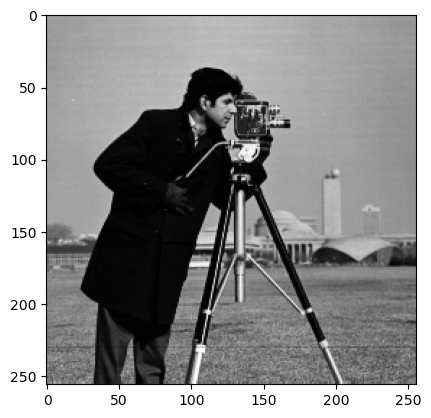

In [6]:
plt.imshow(image, cmap="gray")
plt.show()

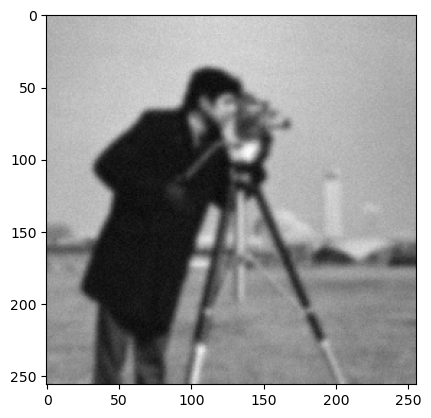

In [141]:
plt.imshow(b.reshape(img_shape), cmap="gray")
plt.show()

# Set up prior

In [142]:
# This can be figured out later
# mask = np.zeros(Lpre.shape[0])
# mask[ Lpre.detail_indices ] = 1
# P = jlinops.Subsampling1DOperator(mask)
#L = P @ Lpre

L = WaveletTransformOperator2D(img_shape, wavelet="haar", level=3)
K = None
Lpinv_factory = lambda wr: L.T @ jlinops.MatrixLinearOperator(sps.diags(1.0/wr))

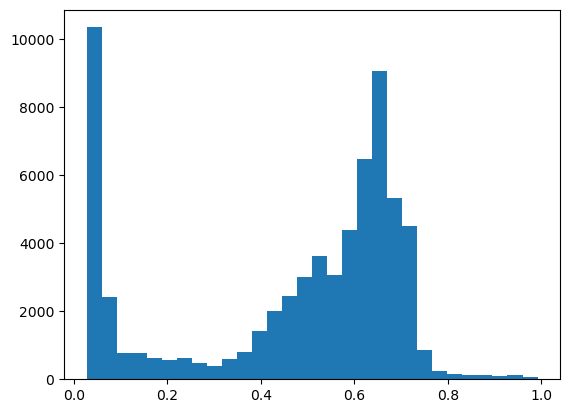

In [143]:
plt.hist(ground_truth, bins=30)
plt.show()

In [144]:
# Set method
method = "dp"

# Weight params
q = 1.0
epsilon = 1e-4
weight_params = {
    "q": q,
    "epsilon": epsilon,
}

# Build solver
mmgks_solver = MMGKS(A, L, b, noise_var=noise_var, Lpinv_factory=Lpinv_factory, K=K, img_shape=img_shape)
gks_solver = VanillaGKS(A, L, b, noise_var=noise_var, Lpinv_factory=Lpinv_factory, K=K, img_shape=img_shape)
mmfk_solver = MMFGK(A, L, b, noise_var=noise_var, Lpinv_factory=Lpinv_factory, K=K, img_shape=img_shape)
mmgkb_solver = MMGKB(A, L, b, noise_var=noise_var, Lpinv_factory=Lpinv_factory, K=K, img_shape=img_shape)

xker = None
ground_truth = ground_truth.copy()

In [145]:
n_its = 130

vdata = gks_solver.solve(n_iter=n_its, init_dim=5, x0=None, lambdah0=1e0, lambdah_min=1e-7, lambdah_max=1e7,
                                    regparam=method, x_true=ground_truth, weight_params={},
                                    regparam_kwargs={"eta":1.01},  xker=xker)

pdata = mmgks_solver.solve_with_priorconditioning(n_iter=n_its, init_dim=5, x0=vdata["x"], lambdah0=vdata["lambdah"], lambdah_min=1e-7, lambdah_max=1e7,
                                                 regparam=method, x_true=ground_truth, weight_params=weight_params, 
                                                 regparam_kwargs={"eta":1.01})


data = mmgks_solver.solve(n_iter=n_its, init_dim=5, x0=vdata["x"], lambdah0=vdata["lambdah"], lambdah_min=1e-7, lambdah_max=1e7,
                                    regparam=method, x_true=ground_truth, weight_params=weight_params,
                                    regparam_kwargs={"eta":1.01}, min_dim=None, max_dim=None, xker=xker)


mmfkdata = mmfk_solver.solve(n_iter=n_its, x0=None, lambdah0=None,
                                                 regparam=method, x_true=ground_truth, ksparsity=None, weight_params=weight_params, refresh_basis=False,
                                                #  regparam_kwargs={"eta":1.01},
                                                #  lambdah_min=1e-7, lambdah_max=1e7,
                                                #  init_dim=5
                                                 )


rmmfkdata = mmfk_solver.solve(n_iter=n_its, x0=None, lambdah0=None,
                                                 regparam=method, x_true=ground_truth, ksparsity=None, weight_params=weight_params, refresh_basis=True,
                                                #  regparam_kwargs={"eta":1.01},
                                                #  lambdah_min=1e-7, lambdah_max=1e7,
                                                #  init_dim=5
                                                 )



mmgkbdata = mmgkb_solver.solve(n_iter=n_its, x0=None, lambdah0=None,
                                                 regparam=method, x_true=ground_truth, ksparsity=None, weight_params=weight_params,
                                                #  regparam_kwargs={"eta":1.01},
                                                #  lambdah_min=1e-7, lambdah_max=1e7,
                                                #  init_dim=5
                                                 )

print("Finished P-GKB")



6.403696257739381
24.378951163852136
30.6680148449734
34.28237319546034
36.49998539257803
37.957039459047465
38.95823574288276
39.66612715599664
40.15748918809064
40.51346250282098
40.77318988890784
40.96284053335661
41.10027792135962
41.20032436106484
41.27037517142443
41.321051542881975
41.356983729113516
41.382568232788564
41.40054703434126
41.41336859053988
41.42262880763566
41.42877720264461
41.433018629332786
41.436028170314685
41.43811471092033
41.43956193271233
41.44059799557117
41.44133499119405
41.44183598292144
41.442186584480595
41.44242077840901
41.44258584383559
41.442701739033474
41.442782570866946
41.44283899789441
41.442877097164654
41.44290372375828
41.442922189272934
41.44293463421998
41.44294272272549
41.44294853389665
41.442952684179424
41.442955523024544
41.44295741347956
41.442958713043936
41.44295959341587
41.442960201654266
41.44296061323565
41.44296089993032
41.44296109514905
41.44296122988429
41.442961324651044
41.44296138899766
41.44296143162505
41.442961460

1e-07


/Users/jonathanlindbloom/Github/IRLS_prec_GSBL/tests/2d_blur_wavelets/../../msolver.py:800: UserWarning: Inequality is NOT satisfied, no solution to the DP problem...
  warnings.warn("Inequality is NOT satisfied, no solution to the DP problem...", UserWarning)


1e-07
1e-07
1e-07
1e-07
1e-07
1e-07
1e-07
1e-07
1e-07
1e-07
1e-07
1e-07
1e-07
1e-07
1e-07
1e-07
1e-07
1e-07
1e-07
1e-07
1e-07
1e-07
1e-07
1e-07
1e-07
1e-07
1e-07
1e-07
1e-07
1e-07
1e-07
1e-07
1e-07
1e-07
1e-07
1e-07
1e-07
1e-07
1e-07
1e-07
1e-07
1e-07
1e-07
1e-07
1e-07
1e-07
1e-07
1e-07
1e-07
1e-07
1e-07
1e-07
1e-07
1e-07
1e-07
1e-07
1e-07
1e-07
1e-07
1e-07
1e-07
1e-07
1e-07
1e-07
1e-07
1e-07
1e-07
1e-07
1e-07
4.594030485095811
6.961462793956231
8.631763663636741
10.088587093543744
11.132753167698425
11.971582815310601
12.810026196580461
13.569727968344978
14.231492764252401
14.82864268260859
15.304820374368509
15.666489878522285
16.0134191696705
16.36397325075426
16.680883560787404
16.947375442721075
17.20982406126315
17.459625438703533
17.669954764521673
17.915096212026505
18.17945553499316
18.425054247066118
18.629342735921828
18.79450598273336
18.979230263642098
19.147880316022054
19.32769485621557
19.479131249828843
19.581311345035882
19.680532730969183
19.775900458981273
19.83996

42.62575677877491
17.850162361302505
26.131784355550916
24.657278592875603
22.920509112047352
22.58894182746844
22.190225700336768
21.792509922081138
21.758393971686203
20.886553415919074
20.827392324539296
20.45615477372055
20.409870082270977
20.48924448518149
20.51373307032158
20.706436856457152
20.75336915871375
20.878886177291342
20.892564224169536
20.87788157665004
20.956512548123012
20.906886931051908
20.86381441353631
20.816755452236507
20.744741461348127
20.764897618284753
20.698077282654257
20.67958288618786
20.684305787579177
20.642661591474216
20.61843874278064
20.622093481393307
20.607235975979226
20.57975436527731
20.53331221299972
20.57399912218221
20.56590198316181
20.555115493273416
20.620011715138602
20.654754252018392
20.70935079909562
20.69800590885975
20.73673340641235
20.820491973017646
20.87342473982161
20.98559371643511
20.94431418666404
20.85664868829972
20.85849631684356
20.87962887070217
20.785188660142687
20.617985909051402
20.48969498247243
20.42689485424022

...


generating basis...: 100%|██████████| 129/129 [00:02<00:00, 59.05it/s]


21.54396431954717


generating basis...: 100%|██████████| 130/130 [00:02<00:00, 59.17it/s]

21.550145512139643


Finished P-GKB


# Performance

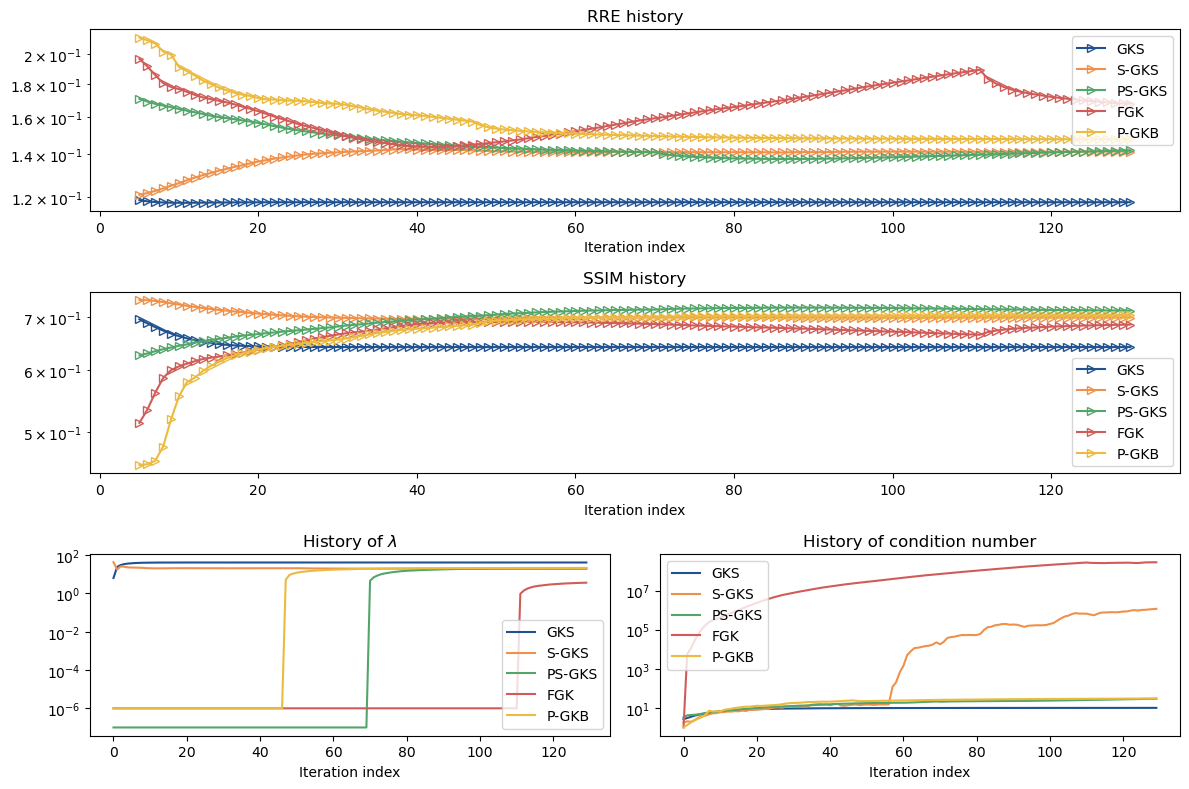

In [222]:
fig = plt.figure(figsize=(12,8) )

gs = gridspec.GridSpec(3, 2, figure=fig)

start_idx = 5
marker = ">"
markerfacecolor = 'none'

ax4 = fig.add_subplot(gs[0, :])
ax4.semilogy([i for i in range(start_idx, len(vdata["rre_history"]))],  vdata["rre_history"][start_idx:], label="GKS", color="C3", marker=marker, markerfacecolor=markerfacecolor)
ax4.semilogy([i for i in range(start_idx, len(vdata["rre_history"]))], data["rre_history"][start_idx:], label="S-GKS", color="C5", marker=marker, markerfacecolor=markerfacecolor)
ax4.semilogy([i for i in range(start_idx, len(vdata["rre_history"]))], pdata["rre_history"][start_idx:], label="PS-GKS", color="C4", marker=marker, markerfacecolor=markerfacecolor)
ax4.semilogy([i for i in range(start_idx, len(vdata["rre_history"]))], mmfkdata["rre_history"][start_idx:], label="FGK", color="C6", marker=marker, markerfacecolor=markerfacecolor)
ax4.semilogy([i for i in range(start_idx, len(vdata["rre_history"]))], mmgkbdata["rre_history"][start_idx:], label="P-GKB", color="C1", marker=marker, markerfacecolor=markerfacecolor)
ax4.legend()
ax4.set_xlabel("Iteration index")
ax4.set_title("RRE history")



ax3 = fig.add_subplot(gs[1, :])
ax3.semilogy([i for i in range(start_idx, len(vdata["rre_history"]))], vdata["ssim_history"][start_idx:], label="GKS", color="C3", marker=marker, markerfacecolor=markerfacecolor)
ax3.semilogy([i for i in range(start_idx, len(vdata["rre_history"]))], data["ssim_history"][start_idx:], label="S-GKS", color="C5", marker=marker, markerfacecolor=markerfacecolor)
ax3.semilogy([i for i in range(start_idx, len(vdata["rre_history"]))], pdata["ssim_history"][start_idx:], label="PS-GKS", color="C4", marker=marker, markerfacecolor=markerfacecolor)
ax3.semilogy([i for i in range(start_idx, len(vdata["rre_history"]))], mmfkdata["ssim_history"][start_idx:], label="FGK", color="C6", marker=marker, markerfacecolor=markerfacecolor)
ax3.semilogy([i for i in range(start_idx, len(vdata["rre_history"]))], mmgkbdata["ssim_history"][start_idx:], label="P-GKB", color="C1", marker=marker, markerfacecolor=markerfacecolor)
ax3.legend()
ax3.set_xlabel("Iteration index")
ax3.set_title("SSIM history")

# ax3 = fig.add_subplot(gs[1, :])
# ax3.semilogy(vdata["haar_history"][start_idx:], label="GKS")
# ax3.semilogy(data["haar_history"][start_idx:], label="S-GKS")
# ax3.semilogy(pdata["haar_history"][start_idx:], label="PS-GKS")
# ax3.semilogy(mmfkdata["haar_history"][start_idx:], label="FGK")
# ax3.semilogy(mmgkbdata["haar_history"][start_idx:], label="P-GKB")
# ax3.legend()


ax1 = fig.add_subplot(gs[2, 0])
ax1.semilogy(vdata["lambda_history"], label="GKS", color="C3")
ax1.semilogy(data["lambda_history"], label="S-GKS", color="C5")
ax1.semilogy(pdata["lambda_history"], label="PS-GKS", color="C4")
ax1.semilogy(mmfkdata["lambda_history"], label="FGK", color="C6")
ax1.semilogy(mmgkbdata["lambda_history"], label="P-GKB", color="C1")
ax1.legend(loc="lower right")
ax1.set_title("History of $\lambda$")
ax1.set_xlabel("Iteration index")



ax2 = fig.add_subplot(gs[2, 1])
ax2.semilogy(vdata["cond_ests"], label="GKS", color="C3")
ax2.semilogy(data["cond_ests"], label="S-GKS", color="C5")
ax2.semilogy(pdata["cond_ests"], label="PS-GKS", color="C4")
ax2.semilogy(mmfkdata["cond_ests"], label="FGK", color="C6")
ax2.semilogy(mmgkbdata["cond_ests"], label="P-GKB", color="C1")
ax2.legend(loc="upper left")
ax2.set_title("History of condition number")
ax2.set_xlabel("Iteration index")

fig.tight_layout()
fig.savefig("2d_camera_performance_mm.png", dpi=250, bbox_inches=None)
fig.savefig("2d_camera_performance_mm.eps", format="eps", dpi=250, bbox_inches=None)


plt.show()

# Reconstruction

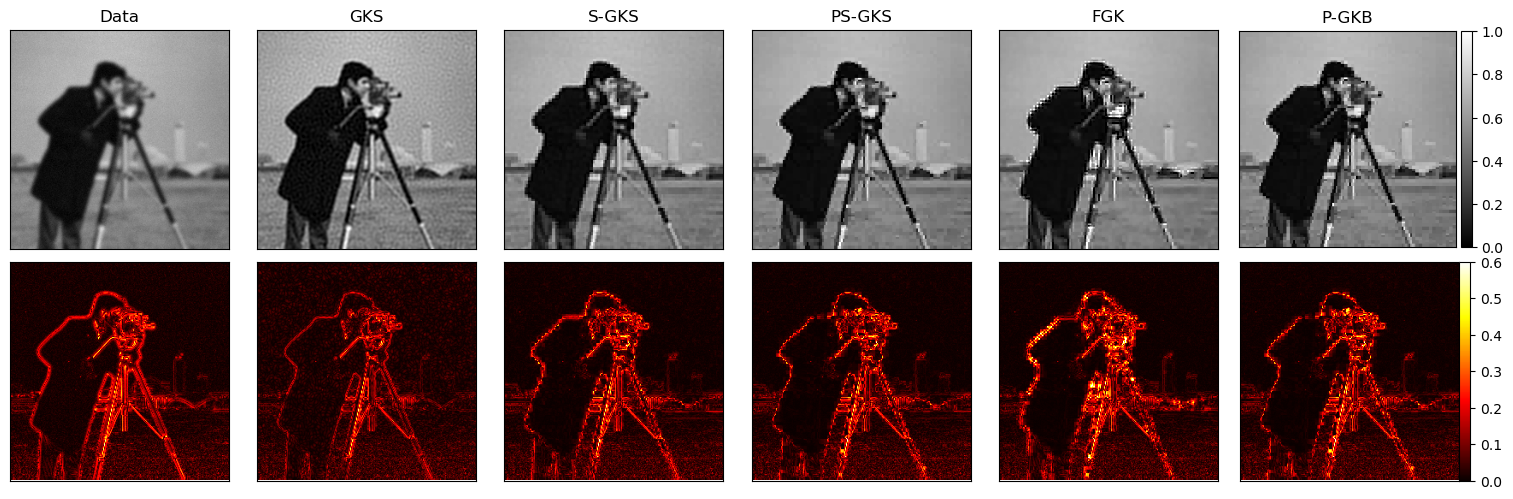

In [239]:
err_cmap = "hot"

vbound = 0.6

fig, axs = plt.subplots(2,6,figsize=(15.3,5))


# Observed
axs[0,0].imshow(b.reshape(img_shape), cmap="gray", vmin=0, vmax=1)
axs[0,0].set_title("Data")
axs[0,0].set_xticks([])
axs[0,0].set_yticks([])

axs[1,0].imshow(np.abs( b.reshape(img_shape) - ground_truth.reshape(img_shape) ), cmap=err_cmap, vmin=0, vmax=vbound)
axs[1,0].set_xticks([])
axs[1,0].set_yticks([])



# Tikhonov
axs[0,1].imshow(vdata["x"].reshape(img_shape), cmap="gray", vmin=0, vmax=1)
axs[0,1].set_title("GKS")
axs[0,1].set_xticks([])
axs[0,1].set_yticks([])

axs[1,1].imshow(np.abs( vdata["x"].reshape(img_shape) - ground_truth.reshape(img_shape) ), cmap=err_cmap, vmin=0, vmax=vbound)
axs[1,1].set_xticks([])
axs[1,1].set_yticks([])


# S-GKS
axs[0,2].imshow(data["x"].reshape(img_shape), cmap="gray", vmin=0, vmax=1)
axs[0,2].set_title("S-GKS")
axs[0,2].set_xticks([])
axs[0,2].set_yticks([])

axs[1,2].imshow(np.abs( data["x"].reshape(img_shape) - ground_truth.reshape(img_shape) ), cmap=err_cmap, vmin=0, vmax=vbound)
axs[1,2].set_xticks([])
axs[1,2].set_yticks([])


# PS-GKS
axs[0,3].imshow(pdata["x"].reshape(img_shape), cmap="gray", vmin=0, vmax=1)
axs[0,3].set_title("PS-GKS")
axs[0,3].set_xticks([])
axs[0,3].set_yticks([])

axs[1,3].imshow(np.abs( pdata["x"].reshape(img_shape) - ground_truth.reshape(img_shape) ), cmap=err_cmap, vmin=0, vmax=vbound)
axs[1,3].set_xticks([])
axs[1,3].set_yticks([])


# FGK
axs[0,4].imshow(mmfkdata["x"].reshape(img_shape), cmap="gray", vmin=0, vmax=1)
axs[0,4].set_title("FGK")
axs[0,4].set_xticks([])
axs[0,4].set_yticks([])

axs[1,4].imshow(np.abs( mmfkdata["x"].reshape(img_shape) - ground_truth.reshape(img_shape) ), cmap=err_cmap, vmin=0, vmax=vbound)
axs[1,4].set_xticks([])
axs[1,4].set_yticks([])



# PS-GKS restarting
im = axs[0,5].imshow(mmgkbdata["x"].reshape(img_shape), cmap="gray", vmin=0, vmax=1)
axs[0,5].set_title("P-GKB")
axs[0,5].set_xticks([])
axs[0,5].set_yticks([])
divider = make_axes_locatable(axs[0,5])
cax = divider.append_axes("right", size="5%", pad=0.05)
fig.colorbar(im, cax=cax)

im = axs[1,5].imshow(np.abs(mmgkbdata["x"].reshape(img_shape) - ground_truth.reshape(img_shape)), cmap=err_cmap, vmin=0, vmax=vbound)
axs[1,5].set_xticks([])
axs[1,5].set_yticks([])
divider = make_axes_locatable(axs[1,5])
cax = divider.append_axes("right", size="5%", pad=0.00)
fig.colorbar(im, cax=cax)

fig.tight_layout()

fig.savefig("2d_camera_reconstructions_mm.png", dpi=250, bbox_inches=None)
fig.savefig("2d_camera_reconstructions_mm.eps", format="eps", dpi=250, bbox_inches=None)


plt.show()

# Basis vectors

In [154]:
np.amax(np.abs(data["V"][:,:]))

0.1890169249359265

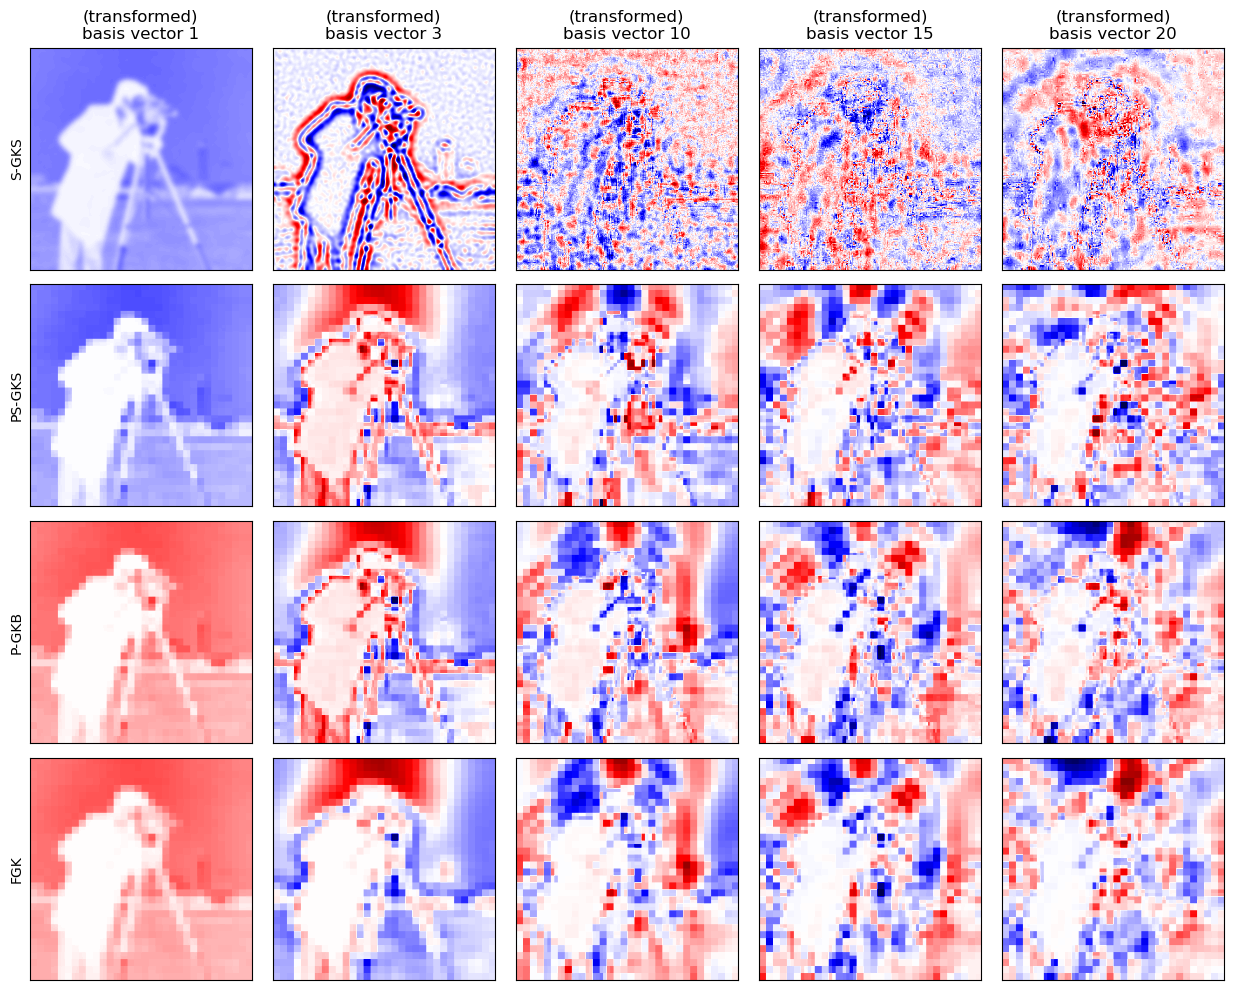

In [170]:
cmap = "seismic"
vbound = 0.1*0.189

kks = [0, 2, 9, 14, 19]

fig, axs = plt.subplots(4,5,figsize=(12.5,10))

for j, kk in enumerate(kks):

    axs[0,j].imshow(data["V"][:,kk].reshape(img_shape), cmap=cmap, vmin=-vbound, vmax=vbound)
    axs[0,j].set_title(f"S-GKS basis vector {kk+1}")
    axs[0,j].set_xticks([])
    axs[0,j].set_yticks([])
    if j == 0:
        axs[0,0].set_ylabel(f"S-GKS")
    axs[0,j].set_title(f"(transformed)\nbasis vector {kk+1}")


for j, kk in enumerate(kks):

    axs[1,j].imshow( ( (pdata["Lopinv"] @ pdata["V"][:,kk])/np.linalg.norm(pdata["Lopinv"] @ pdata["V"][:,kk]) ).reshape(img_shape), cmap=cmap, vmin=-vbound, vmax=vbound)
    axs[1,j].set_xticks([])
    axs[1,j].set_yticks([])
    if j == 0:
        axs[1,j].set_ylabel(f"PS-GKS")


for j, kk in enumerate(kks):

    axs[2,j].imshow( ( (mmgkbdata["Lopinv"] @ mmgkbdata["V"][:,kk])/np.linalg.norm(mmgkbdata["Lopinv"] @ mmgkbdata["V"][:,kk]) ).reshape(img_shape), cmap=cmap, vmin=-vbound, vmax=vbound)
    axs[2,j].set_xticks([])
    axs[2,j].set_yticks([])
    if j == 0:
        axs[2,j].set_ylabel(f"P-GKB")



for j, kk in enumerate(kks):

    axs[3,j].imshow( ( mmfkdata["Z"][:,kk]/np.linalg.norm(mmfkdata["Z"][:,kk]) ).reshape(img_shape), cmap=cmap, vmin=-vbound, vmax=vbound)
    axs[3,j].set_xticks([])
    axs[3,j].set_yticks([])
    if j == 0:
        axs[3,j].set_ylabel(f"FGK")


fig.tight_layout()

fig.savefig("2d_camera_basis_vectors_mm.png", dpi=250, bbox_inches=None)
fig.savefig("2d_camera_basis_vectors_mm.eps", format="eps", dpi=250, bbox_inches=None)


plt.show()

In [ ]:
fig = plt.figure(figsize=(18,10))

gs = gridspec.GridSpec(3, 3, figure=fig)

ax1 = fig.add_subplot(gs[2, 2])
ax1.semilogy(vdata["lambda_history"], label="GKS", color="C3")
ax1.semilogy(data["lambda_history"], label="S-GKS", color="C5")
ax1.semilogy(resdata["lambda_history"], label="S-GKS (restarting)", color="C5", ls="--")
ax1.semilogy(recdata["lambda_history"], label="S-GKS (recycling)", color="C5", ls=":")
ax1.semilogy(pdata["lambda_history"], label="PS-GKS", color="C4")
ax1.semilogy(respdata["lambda_history"], label="PS-GKS (restarting)", color="C4", ls="--")
ax1.set_title("History of $\\lambda$")
ax1.set_xlabel("Iteration index")
ax1.legend()


ax2 = fig.add_subplot(gs[0, 0])
ax2.semilogy(vdata["rre_history"], label="GKS", color="C3")
ax2.semilogy(data["rre_history"], label="S-GKS", color="C5")
ax2.semilogy(resdata["rre_history"], label="S-GKS (restarting)", color="C5", ls="--")
ax2.semilogy(recdata["rre_history"], label="S-GKS (recycling)", color="C5", ls=":")
ax2.semilogy(pdata["rre_history"], label="PS-GKS", color="C4")
ax2.semilogy(respdata["rre_history"], label="PS-GKS (restarting)", color="C4", ls="--")
ax2.set_title("RRE")
ax2.set_xlabel("Iteration index")
ax2.legend()


ax3 = fig.add_subplot(gs[0, 1])
ax3.semilogy(vdata["ssim_history"], label="GKS")
ax3.semilogy(data["ssim_history"], label="S-GKS", color="C5")
ax3.semilogy(resdata["ssim_history"], label="S-GKS (restarting)", color="C5", ls="--")
ax3.semilogy(recdata["ssim_history"], label="S-GKS (recycling)", color="C5", ls=":")
ax3.semilogy(pdata["ssim_history"], label="PS-GKS", color="C4")
ax3.semilogy(respdata["ssim_history"], label="PS-GKS (restarting)", color="C4", ls="--")
ax3.set_title("SSIM")
ax3.set_xlabel("Iteration index")
ax3.legend()



ax7 = fig.add_subplot(gs[0, 2])
ax7.semilogy(vdata["haar_history"], label="GKS")
ax7.semilogy(data["haar_history"], label="S-GKS", color="C5")
ax7.semilogy(resdata["haar_history"], label="S-GKS (restarting)", color="C5", ls="--")
ax7.semilogy(recdata["haar_history"], label="S-GKS (recycling)", color="C5", ls=":")
ax7.semilogy(pdata["haar_history"], label="PS-GKS", color="C4")
ax7.semilogy(respdata["haar_history"], label="PS-GKS (restarting)", color="C4", ls="--")
ax7.set_title("HaarPSI")
ax7.set_xlabel("Iteration index")
ax7.legend()




ax5 = fig.add_subplot(gs[1, :2]) 
ax5.semilogy(1.0/resdata["w"][:int(len(resdata["w"])/2)].reshape(img_shape)[128,:], label="S-GKS (restarting)", color="C5", ls="--")
ax5.semilogy(1.0/respdata["w"][:int(len(resdata["w"])/2)].reshape(img_shape)[128,:], label="PS-GKS (restarting)", color="C4", ls="--")
ax5.set_xlabel("Horizontal cross section at index 128")
ax5.set_title("$1/w$")
ax5.legend()



ax6 = fig.add_subplot(gs[1, 2])
ax6.semilogy(vdata["cond_ests"], label="GKS", color="C3")
ax6.semilogy(data["cond_ests"], label="S-GKS", color="C5")
ax6.semilogy(resdata["cond_ests"], label="S-GKS (restarting)", color="C5", ls="--")
ax6.semilogy(recdata["cond_ests"], label="S-GKS (recycling)", color="C5", ls=":")
ax6.semilogy(pdata["cond_ests"], label="PS-GKS", color="C2")
ax6.semilogy(respdata["cond_ests"], label="PS-GKS (restarting)", color="C4", ls="--")
ax6.set_title("Condition number")
ax6.set_xlabel("Iteration index")
ax6.legend()





ax4 = fig.add_subplot(gs[2, :2]) 
ax4.plot(x_true.reshape(img_shape)[128,:], label="Ground truth", color="k", alpha=0.8, lw=0.5)
ax4.plot(vdata["x"].reshape(img_shape)[128,:], label="GKS", color="C3", ls="--")
ax4.plot(resdata["x"].reshape(img_shape)[128,:], label="S-GKS (restarting)", color="C5", ls="--")
ax4.plot(respdata["x"].reshape(img_shape)[128,:], label="PS-GKS (restarting)", color="C4", ls="--")
ax4.set_xlabel("Horizontal cross section at index 128")
ax4.legend()



fig.tight_layout()
# fig.savefig("2d_shepp_performance_mm.png", dpi=250, bbox_inches=None)
# fig.savefig("2d_shepp_performance_mm.eps", format="eps", dpi=250, bbox_inches=None)

plt.show()

# Other plots

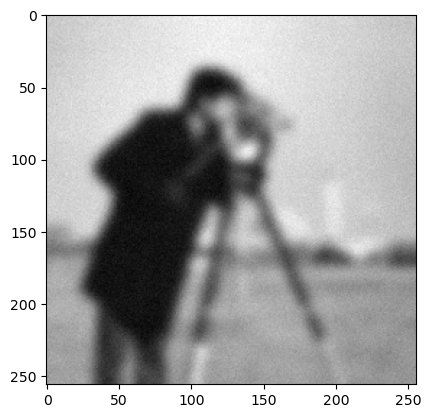

In [135]:
plt.imshow(b.reshape(img_shape), cmap="gray")
plt.show()

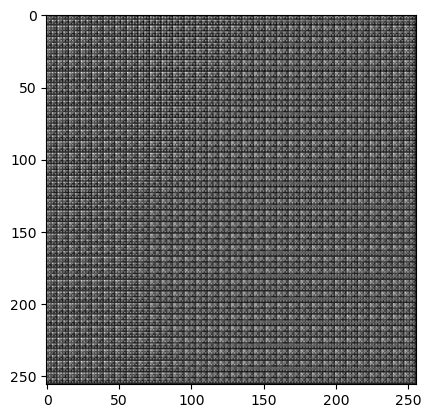

In [136]:
plt.imshow( (L.T @ b).reshape(img_shape), cmap="gray")
plt.show()

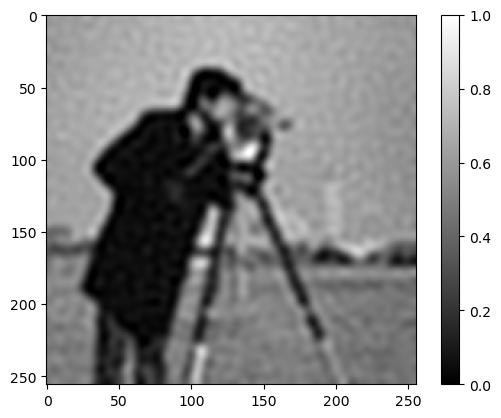

In [116]:
plt.imshow(vdata["x"].reshape(img_shape), cmap="gray", vmin=0.0, vmax=1.0)
plt.colorbar()
plt.show()

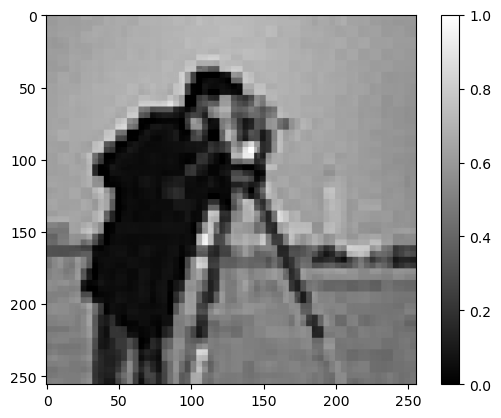

In [117]:
plt.imshow(data["x"].reshape(img_shape), cmap="gray", vmin=0.0, vmax=1.0)
plt.colorbar()
plt.show()

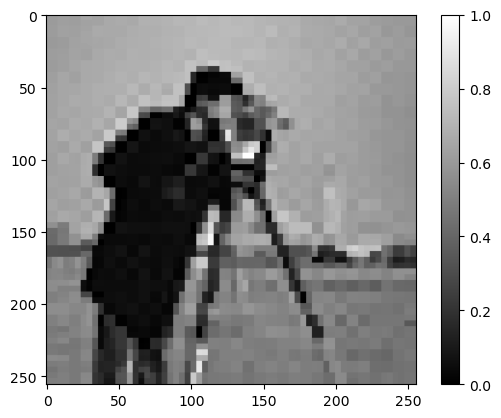

In [118]:
plt.imshow(pdata["x"].reshape(img_shape), cmap="gray", vmin=0.0, vmax=1.0)
plt.colorbar()
plt.show()

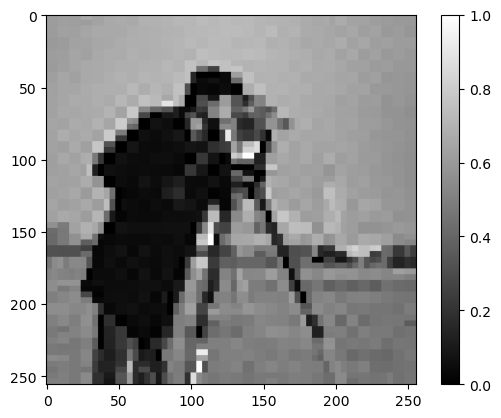

In [119]:
plt.imshow(mmgkbdata["x"].reshape(img_shape), cmap="gray", vmin=0.0, vmax=1.0)
plt.colorbar()
plt.show()

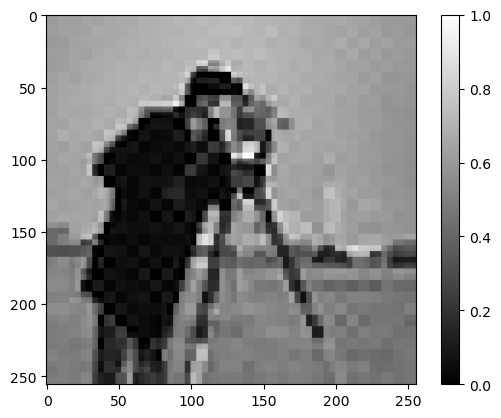

In [120]:
plt.imshow(mmfkdata["x"].reshape(img_shape), cmap="gray", vmin=0.0, vmax=1.0)
plt.colorbar()
plt.show()

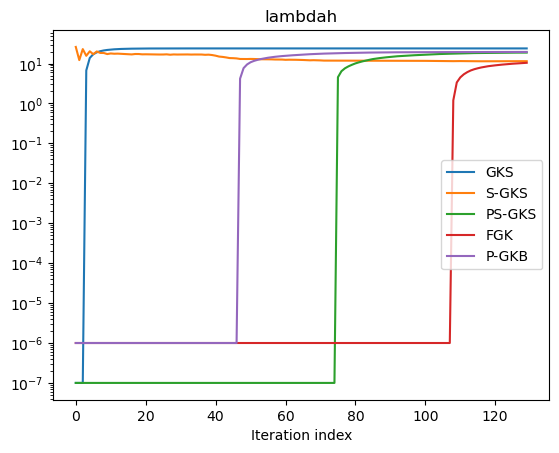

In [121]:
plt.semilogy(vdata["lambda_history"], label="GKS")
plt.semilogy(data["lambda_history"], label="S-GKS")
# plt.semilogy(data_opt["rre_history"], label="S-GKS (optimal)", ls="--", alpha=0.7)
plt.semilogy(pdata["lambda_history"], label="PS-GKS")
plt.semilogy(mmfkdata["lambda_history"], label="FGK")
plt.semilogy(mmgkbdata["lambda_history"], label="P-GKB")
# plt.semilogy(pdata_opt["rre_history"], label="PS-GKS (optimal)", ls="--", alpha=0.7)
#plt.semilogy(rdata["rre_history"], label="Restarted", ls="--", alpha=0.7)
plt.title("lambdah")
plt.xlabel("Iteration index")
plt.legend()
plt.show()

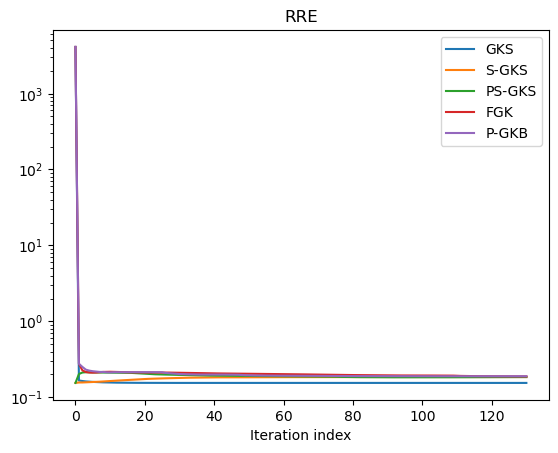

In [122]:
plt.semilogy(vdata["rre_history"], label="GKS")
plt.semilogy(data["rre_history"], label="S-GKS")
# plt.semilogy(data_opt["rre_history"], label="S-GKS (optimal)", ls="--", alpha=0.7)
plt.semilogy(pdata["rre_history"], label="PS-GKS")
plt.semilogy(mmfkdata["rre_history"], label="FGK")
plt.semilogy(mmgkbdata["rre_history"], label="P-GKB")
# plt.semilogy(pdata_opt["rre_history"], label="PS-GKS (optimal)", ls="--", alpha=0.7)
#plt.semilogy(rdata["rre_history"], label="Restarted", ls="--", alpha=0.7)
plt.title("RRE")
plt.xlabel("Iteration index")
plt.legend()
plt.show()

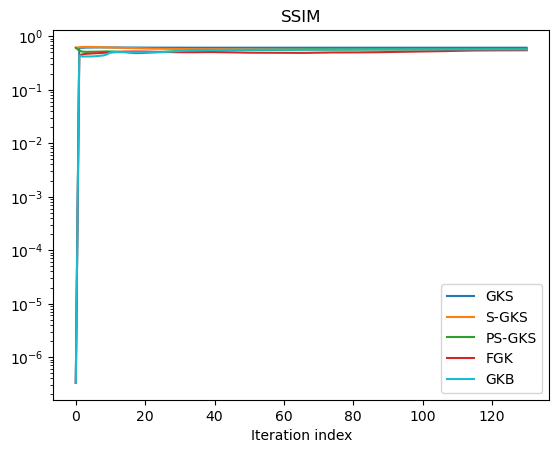

In [125]:
plt.semilogy(vdata["ssim_history"], label="GKS")
plt.semilogy(data["ssim_history"], label="S-GKS")
# plt.semilogy(data_opt["rre_history"], label="S-GKS (optimal)", ls="--", alpha=0.7)
plt.semilogy(pdata["ssim_history"], label="PS-GKS")
plt.semilogy(mmfkdata["ssim_history"], label="FGK")
# plt.semilogy(pdata_opt["rre_history"], label="PS-GKS (optimal)", ls="--", alpha=0.7)
#plt.semilogy(rdata["rre_history"], label="Restarted", ls="--", alpha=0.7)
plt.semilogy(mmgkbdata["ssim_history"], label="GKB", color="C9")
plt.title("SSIM")
plt.xlabel("Iteration index")
plt.legend()
plt.show()

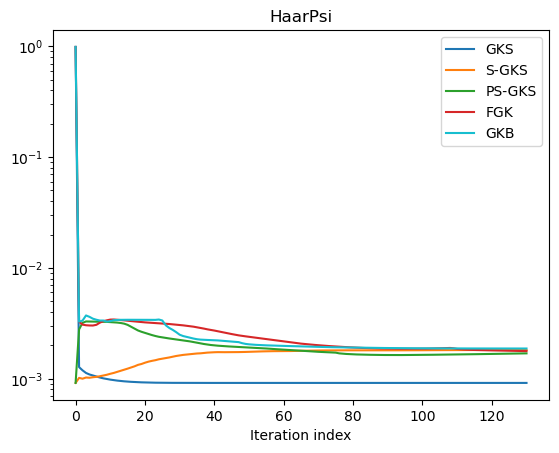

In [126]:
plt.semilogy(1-vdata["haar_history"], label="GKS")
plt.semilogy(1-data["haar_history"], label="S-GKS")
# plt.semilogy(data_opt["rre_history"], label="S-GKS (optimal)", ls="--", alpha=0.7)
plt.semilogy(1-pdata["haar_history"], label="PS-GKS")
plt.semilogy(1-mmfkdata["haar_history"], label="FGK")
# plt.semilogy(pdata_opt["rre_history"], label="PS-GKS (optimal)", ls="--", alpha=0.7)
#plt.semilogy(rdata["rre_history"], label="Restarted", ls="--", alpha=0.7)
plt.semilogy(1-mmgkbdata["haar_history"], label="GKB", color="C9")
plt.title("HaarPsi")
plt.xlabel("Iteration index")
plt.legend()
plt.show()

In [24]:
pdata["haar_history"]

array([0.99977895, 0.99893879, 0.99877378, 0.99870822, 0.99871015,
       0.9987684 , 0.99883229, 0.99887182, 0.99890467, 0.99893616,
       0.99896992, 0.99899804, 0.99902043, 0.99904554, 0.99907053,
       0.99909251, 0.99911082, 0.99912711, 0.99914394, 0.99916236,
       0.99918311, 0.99920906, 0.99923647, 0.99926293, 0.99928414,
       0.9993028 , 0.99932018, 0.99933764, 0.99935618, 0.99937194,
       0.99938765, 0.99940613, 0.99942366, 0.99944045, 0.99945714,
       0.99947115, 0.99948362, 0.99949556, 0.99950773, 0.99951852,
       0.99952721, 0.99953537, 0.99954417, 0.99955255, 0.99956083,
       0.99956818, 0.99957536, 0.99958231, 0.9995889 , 0.99959529,
       0.99960063, 0.99960472, 0.99960906, 0.99961346, 0.99961734,
       0.99962098, 0.99962459, 0.99962742, 0.99962972, 0.9996319 ,
       0.99963382, 0.99963526, 0.99963669, 0.99963862, 0.99964097,
       0.99964298, 0.99964476, 0.99964625, 0.99964718, 0.99964826,
       0.99965394, 0.99966057, 0.99966447, 0.99966765, 0.99967

In [25]:
vdata["haar_history"]

array([9.31203851e-04, 9.99680055e-01, 9.99707518e-01, 9.99728855e-01,
       9.99744216e-01, 9.99755268e-01, 9.99762842e-01, 9.99768336e-01,
       9.99772198e-01, 9.99774815e-01, 9.99776571e-01, 9.99777668e-01,
       9.99778344e-01, 9.99778713e-01, 9.99778885e-01, 9.99778956e-01,
       9.99778968e-01, 9.99778972e-01, 9.99778982e-01, 9.99779013e-01,
       9.99779031e-01, 9.99779029e-01, 9.99779020e-01, 9.99779011e-01,
       9.99779003e-01, 9.99778992e-01, 9.99778986e-01, 9.99778977e-01,
       9.99778971e-01, 9.99778966e-01, 9.99778962e-01, 9.99778960e-01,
       9.99778961e-01, 9.99778962e-01, 9.99778961e-01, 9.99778960e-01,
       9.99778958e-01, 9.99778957e-01, 9.99778955e-01, 9.99778954e-01,
       9.99778953e-01, 9.99778952e-01, 9.99778951e-01, 9.99778951e-01,
       9.99778951e-01, 9.99778951e-01, 9.99778951e-01, 9.99778951e-01,
       9.99778951e-01, 9.99778951e-01, 9.99778951e-01, 9.99778951e-01,
       9.99778951e-01, 9.99778951e-01, 9.99778951e-01, 9.99778951e-01,
      

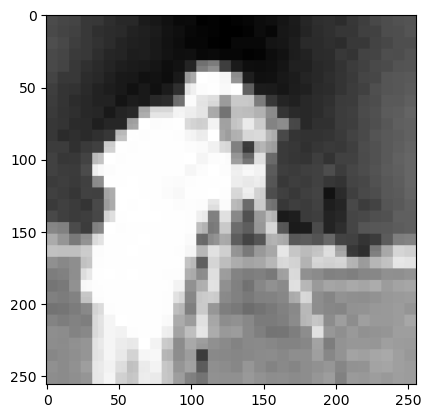

In [127]:
plt.imshow( (pdata["Lopinv"] @ pdata["V"][:,0]).reshape(img_shape) , cmap="gray")
plt.show()

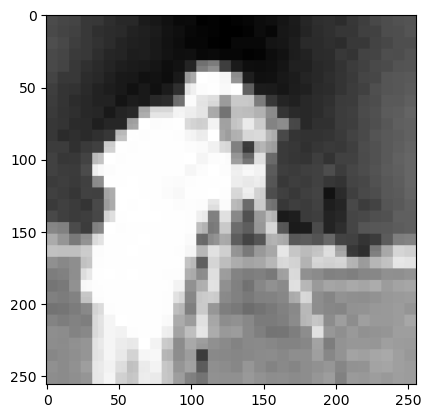

In [128]:
plt.imshow( (pdata["Lopinv"] @ pdata["V"][:,0]).reshape(img_shape) , cmap="gray")
plt.show()

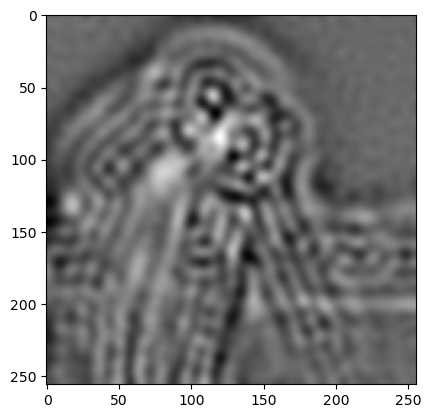

In [129]:
plt.imshow( (vdata["V"][:,5]).reshape(img_shape) , cmap="gray")
plt.show()

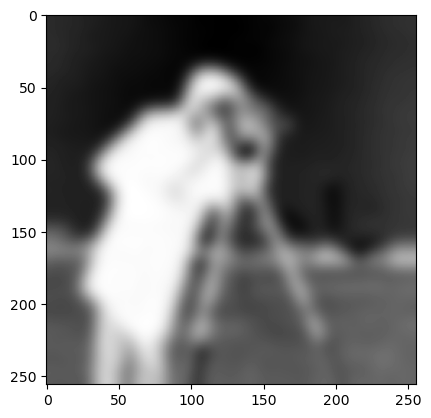

In [130]:
plt.imshow( (data["V"][:,0]).reshape(img_shape) , cmap="gray")
plt.show()

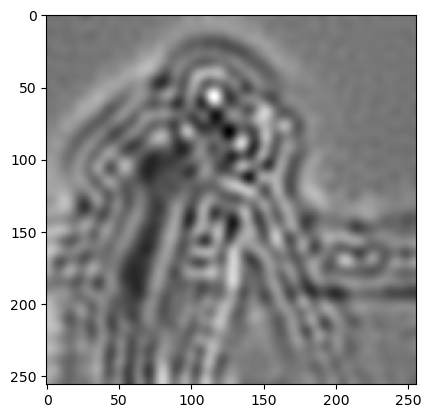

In [131]:
plt.imshow( (data["V"][:,4]).reshape(img_shape) , cmap="gray")
plt.show()

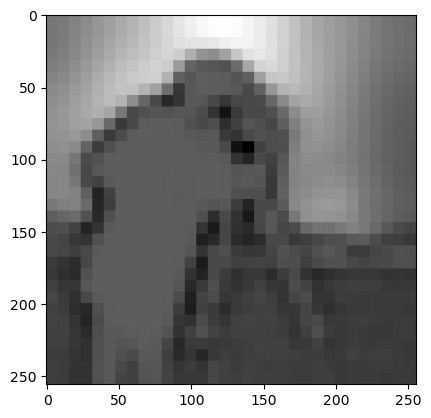

In [132]:
plt.imshow( (mmfkdata["Z"][:,1]).reshape(img_shape) , cmap="gray")
plt.show()

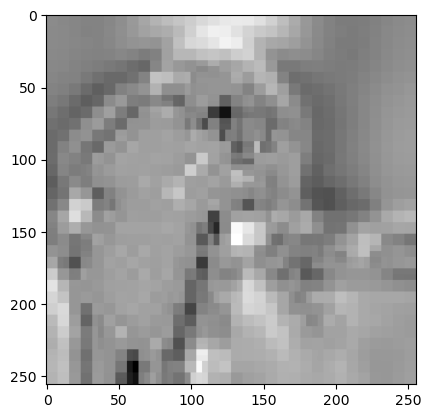

In [133]:
plt.imshow( (mmgkbdata["Lopinv"] @ ( (mmgkbdata["V"][:,4]) ) ).reshape(img_shape) , cmap="gray")
plt.show()

In [134]:
mmgkbdata.keys()

dict_keys(['x', 'V', 'U', 'B', 'w', 'Lopinv', 'lambda_history', 'cond_ests', 'rre_history', 'ssim_history', 'haar_history'])